# Module 4 — Recalibrate QRS, ARS and HI weights (global sensitivity analysis)

$$QRS = a\,\overline{Q_{sem}} + b\,\overline{Q_{key}} + c\,\overline{Q_{rerank}} \qquad
ARS = x\,\overline{A_{sem}} + y\,\overline{A_{key}} + z\,\overline{A_{rerank}} \qquad
HI = 1 - \frac{p\,QRS + q\,ARS}{p+q}$$

**Goal:** find weights where **HI is high for incorrect answers**. We measure this with PR-AUC (average precision),
using *incorrect* as the positive class.

**Calibration data:** `03_calibration_eval_dataset.csv` from 03c: the 163 original BioASQ questions, judged against their ground truths. Every attendee uses this same set, so your results should be close to the instructor's.

In [1]:
import sys
from pathlib import Path

# Make the repo root importable whether Jupyter was started from the root or this folder
ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from common.mygpt_client import MyGPTClient, outputs_dir, load_fallback_pubmedqa  # noqa: E402
OUT = outputs_dir()

In [2]:
import ast, itertools, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

FORCE_FALLBACK = False
DEFAULT = {"Q": (4, -4, -1), "A": (5, -2, 0), "pq": (1, 2)}     # MyGPT backend defaults (testdb/models.py)
GRID = np.arange(-5, 6)                                       # candidate integer weights -5..5

## 1. Load the benchmark and rebuild the score components

In [3]:
def mean_list(s):
    try:
        v = ast.literal_eval(s) if isinstance(s, str) else []
        return float(np.mean(v)) if len(v) else 0.0
    except Exception:
        return np.nan

def entail_share(*cols):
    tags = []
    for s in cols:
        try:
            tags += [t[0] for t in ast.literal_eval(s)] if isinstance(s, str) else []
        except Exception:
            pass
    return tags.count("entailment") / len(tags) if tags else 0.0

calibration = OUT / "03_calibration_eval_dataset.csv"
pilot = OUT / "03_eval_dataset.csv"
own = calibration if calibration.exists() else pilot
if own.exists() and not FORCE_FALLBACK:
    df = pd.read_csv(own)
else:
    df = load_fallback_pubmedqa()
    df["label"] = (df["correctness"] == "correct").astype(int)
    df = df.rename(columns={"hallucination_index": "HI"})

if "vector_scores_question" in df:          # PubMedQA format: rebuild from per-chunk lists
    source = "per-chunk lists"
    df["Qsem"] = df["vector_scores_question"].map(mean_list)
    df["Qkey"] = df["bm25_scores_question"].map(mean_list)
    df["Qrank"] = df["reranked_score"].map(mean_list)
    df["Asem"] = df["vector_scores"].map(mean_list)
    df["Akey"] = df["bm25_scores"].map(mean_list)
    df["Arank"] = [entail_share(a, b) for a, b in zip(df["rerank_sentiments"], df.get("rerank_sentiments.1", df["rerank_sentiments"]))]
else:                                        # own benchmark: aggregated scores returned by MyGPT
    source = "MyGPT aggregate scores"
    df["Arank"] = df.get("Arank", 0.0)

COMP = ["Qsem", "Qkey", "Qrank", "Asem", "Akey", "Arank"]
df[["Qrank", "Arank"]] = df[["Qrank", "Arank"]].fillna(0)      # no reranker -> 0
df = df.dropna(subset=["label", "Qsem", "Qkey", "Asem", "Akey"] + [c for c in ["HI"] if c in df]).reset_index(drop=True)
X = df[COMP].astype(float)
X = (X - X.min()) / (X.max() - X.min()).replace(0, 1)       # min-max each component to [0, 1]
y = (df["label"].astype(int) == 0).astype(int).to_numpy()  # 1 = incorrect answer (what HI should flag)

print(f"{len(df)} questions from {own.name if own.exists() and not FORCE_FALLBACK else 'PubMedQA fallback'} ({source})")
print(f"incorrect answers: {y.sum()}  -> PR-AUC of a random score = {y.mean():.3f}")
if own == pilot and not FORCE_FALLBACK:
    print("WARNING: calibration dataset not found; using the pilot set. Run 03c on the original BioASQ questions after the 03b κ check.")
if len(df) < 50:
    print("WARNING: fewer than 50 labelled questions; treat optimized weights as illustrative.")
if y.sum() < 5:
    print("WARNING: fewer than 5 incorrect examples; weight calibration may be unstable.")
X.describe().round(2)

163 questions from 03_calibration_eval_dataset.csv (MyGPT aggregate scores)
incorrect answers: 53  -> PR-AUC of a random score = 0.325


,Qsem,Qkey,Qrank,Asem,Akey,Arank
count,163.00,163.00,163.00,163.00,163.00,163.0
mean,0.78,0.45,0.80,0.76,0.25,0.0
std,0.24,0.23,0.25,0.22,0.21,0.0
min,0.00,0.00,0.00,0.00,0.00,0.0
25%,0.78,0.32,0.72,0.75,0.09,0.0
50%,0.85,0.45,0.87,0.81,0.20,0.0
75%,0.89,0.58,0.98,0.87,0.35,0.0
max,1.00,1.00,1.00,1.00,1.00,0.0


## 2. Score functions and the default weights

In [4]:
def minmax(v):
    rng = v.max() - v.min()
    return (v - v.min()) / rng if rng else np.zeros_like(v)

def qrs(w): return minmax(X[["Qsem", "Qkey", "Qrank"]].to_numpy() @ np.asarray(w, float))
def ars(w): return minmax(X[["Asem", "Akey", "Arank"]].to_numpy() @ np.asarray(w, float))
def hi(q, a, p, qq): return 1 - (p * q + qq * a) / (p + qq)

def prauc(score_of_incorrect, idx=None):
    yy, ss = (y, score_of_incorrect) if idx is None else (y[idx], score_of_incorrect[idx])
    return average_precision_score(yy, ss) if yy.sum() else np.nan

base_q, base_a = qrs(DEFAULT["Q"]), ars(DEFAULT["A"])
baseline = {
    "QRS (low = incorrect)": prauc(1 - base_q),
    "ARS (low = incorrect)": prauc(1 - base_a),
    "HI  (high = incorrect)": prauc(hi(base_q, base_a, *DEFAULT["pq"])),
}
if {"QRS", "ARS", "HI"} <= set(df.columns):     # sanity check against MyGPT's own scores
    baseline["MyGPT stored HI"] = prauc(df["HI"].astype(float).to_numpy())
pd.Series(baseline, name="PR-AUC (default weights)").round(3)

QRS (low = incorrect)     0.384
ARS (low = incorrect)     0.553
HI  (high = incorrect)    0.548
MyGPT stored HI           0.574
Name: PR-AUC (default weights), dtype: float64

## 3. Global grid search over (a, b, c) and (x, y, z)
Scaling all weights by the same positive number gives the same ranking, so a small integer grid covers the useful space.

In [5]:
def grid_search(score_fn):
    rows = []
    for w in itertools.product(GRID, GRID, GRID):
        if not any(w):
            continue
        rows.append((*w, prauc(1 - score_fn(w))))
    return pd.DataFrame(rows, columns=["w1", "w2", "w3", "prauc"]).sort_values("prauc", ascending=False)

q_grid = grid_search(qrs).rename(columns={"w1": "a", "w2": "b", "w3": "c"})
a_grid = grid_search(ars).rename(columns={"w1": "x", "w2": "y", "w3": "z"})
print("Top QRS weights"); display(q_grid.head(5))
print("Top ARS weights"); display(a_grid.head(5))

Top QRS weights


,a,b,c,prauc
1201,4,5,-2,0.561675
938,2,3,-1,0.558949
1080,3,5,-2,0.558639
1322,5,5,-2,0.558207
1070,3,4,-1,0.557527


Top ARS weights


,x,y,z,prauc
1218,5,-5,4,0.563052
778,1,-1,4,0.563052
776,1,-1,2,0.563052
775,1,-1,1,0.563052
774,1,-1,0,0.563052


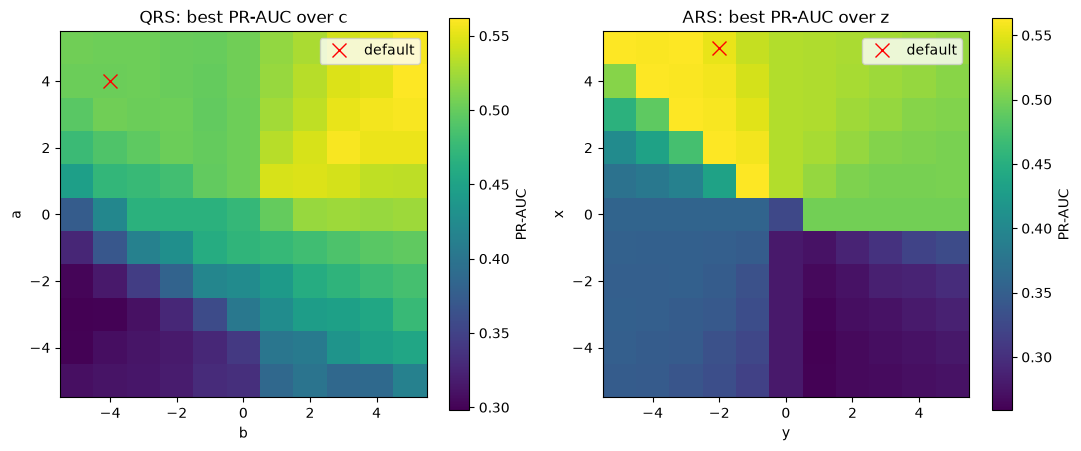

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, grid, (r, c), title in [(axes[0], q_grid, ("a", "b"), "QRS: best PR-AUC over c"),
                                (axes[1], a_grid, ("x", "y"), "ARS: best PR-AUC over z")]:
    heat = grid.groupby([r, c])["prauc"].max().unstack()
    im = ax.imshow(heat.values, origin="lower", cmap="viridis",
                   extent=[GRID[0] - .5, GRID[-1] + .5, GRID[0] - .5, GRID[-1] + .5])
    ax.set_xlabel(c); ax.set_ylabel(r); ax.set_title(title)
    fig.colorbar(im, ax=ax, label="PR-AUC")
d = DEFAULT
axes[0].plot(d["Q"][1], d["Q"][0], "rx", ms=10, label="default"); axes[0].legend()
axes[1].plot(d["A"][1], d["A"][0], "rx", ms=10, label="default"); axes[1].legend()
plt.tight_layout()

**Read the heat map:** a broad bright ridge means many weights work equally well, so the result is robust.
A single bright pixel means the result depends on one exact setting, so treat it with caution.

## 4. Sweep p : q for the hallucination index

best p:q = (5, 5)


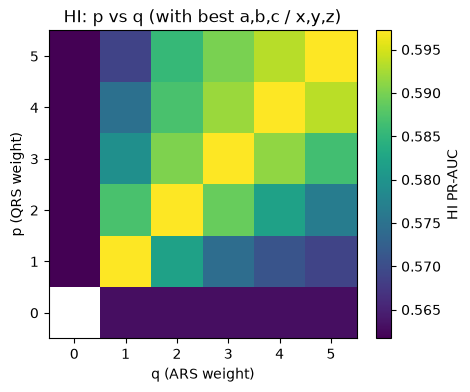

In [7]:
best_Q = tuple(q_grid.iloc[0][["a", "b", "c"]].astype(int))
best_A = tuple(a_grid.iloc[0][["x", "y", "z"]].astype(int))
bq, ba = qrs(best_Q), ars(best_A)

pq = pd.DataFrame([(p, q, prauc(hi(bq, ba, p, q))) for p in range(0, 6) for q in range(0, 6) if p + q],
                  columns=["p", "q", "prauc"])
heat = pq.pivot(index="p", columns="q", values="prauc")
plt.figure(figsize=(5, 4)); plt.imshow(heat.values, origin="lower", cmap="viridis")
plt.xticks(range(6)); plt.yticks(range(6)); plt.xlabel("q (ARS weight)"); plt.ylabel("p (QRS weight)")
plt.colorbar(label="HI PR-AUC"); plt.title("HI: p vs q (with best a,b,c / x,y,z)")
best_pq = tuple(pq.sort_values("prauc", ascending=False).iloc[0][["p", "q"]].astype(int))
print("best p:q =", best_pq)

## 5. Is the improvement real? Bootstrap check
Resample the questions 200 times and compare the HI PR-AUC of the **default** and **recalibrated** weights on each resample.

In [8]:
rng = np.random.default_rng(0)
hi_default = hi(base_q, base_a, *DEFAULT["pq"])
hi_new = hi(bq, ba, *best_pq)

diffs, d_scores, n_scores = [], [], []
for _ in range(200):
    idx = rng.integers(0, len(y), len(y))
    if y[idx].sum() == 0:
        continue
    d, n = prauc(hi_default, idx), prauc(hi_new, idx)
    d_scores.append(d); n_scores.append(n); diffs.append(n - d)

ci = lambda v: f"{np.mean(v):.3f} [{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"
print("HI PR-AUC default     :", ci(d_scores))
print("HI PR-AUC recalibrated:", ci(n_scores))
print(f"recalibrated beats default in {np.mean(np.array(diffs) > 0):.0%} of resamples")
print("(the recalibrated weights were also chosen on this data, so this is optimistic — use a held-out split for reporting)")

HI PR-AUC default     : 0.547 [0.407, 0.667]
HI PR-AUC recalibrated: 0.600 [0.478, 0.709]
recalibrated beats default in 91% of resamples
(the recalibrated weights were also chosen on this data, so this is optimistic — use a held-out split for reporting)


## 6. Save the recommendation

In [9]:
beats = float(np.mean(np.array(diffs) > 0))
recommend_new = beats >= 0.9
chosen_Q, chosen_A, chosen_pq = (best_Q, best_A, best_pq) if recommend_new else (DEFAULT["Q"], DEFAULT["A"], DEFAULT["pq"])

result = {
    "recommendation": "recalibrated" if recommend_new else "keep defaults (improvement not stable)",
    "Qsem_a": int(chosen_Q[0]), "Qkey_b": int(chosen_Q[1]), "Qrank_c": int(chosen_Q[2]),
    "Asem_x": int(chosen_A[0]), "Akey_y": int(chosen_A[1]), "Arank_z": int(chosen_A[2]),
    "QRS_p": int(chosen_pq[0]), "ARS_q": int(chosen_pq[1]),
    "n_questions": int(len(y)), "n_incorrect": int(y.sum()),
    "hi_prauc_default": float(np.mean(d_scores)), "hi_prauc_recalibrated": float(np.mean(n_scores)),
    "bootstrap_win_rate": beats,
}
(OUT / "04_recalibrated_weights.json").write_text(json.dumps(result, indent=2))
result

{'recommendation': 'recalibrated',
 'Qsem_a': 4,
 'Qkey_b': 5,
 'Qrank_c': -2,
 'Asem_x': 5,
 'Akey_y': -5,
 'Arank_z': 4,
 'QRS_p': 5,
 'ARS_q': 5,
 'n_questions': 163,
 'n_incorrect': 53,
 'hi_prauc_default': 0.5468153044454824,
 'hi_prauc_recalibrated': 0.5998046341582004,
 'bootstrap_win_rate': 0.91}

## 7. Apply in MyGPT
In the MyGPT UI open **chat settings**, enter the weights and set *use default* off for QRS/ARS/HI.
Or update the library through the API. This changes the library's stored settings, so uncomment the cell when you're ready.

In [ ]:
# client = MyGPTClient.from_env()
# fields = {k: result[k] for k in ["Qsem_a", "Qkey_b", "Qrank_c", "Asem_x", "Akey_y", "Arank_z", "QRS_p", "ARS_q"]}
# client.update_dataset(**fields)

## Discuss
- Did your field prefer more **keyword** weight (b, y) or more **semantic** weight (a, x) than the defaults? Why might that be?
- Was the improvement stable in the bootstrap? If not, what would you need: more questions, or more incorrect examples?